# 03 - Alert rule: only alert after 2 flagged days in a row

In notebook 02 the blended score flagged about **5.5% of normal days**. That's roughly one false alarm every couple of weeks per user, and people would quickly stop paying attention.

Idea: illness usually lasts **several days** (temperature and resting HR stay up), but random noise is usually just one odd day. So we keep the daily `flag` but only send an `alert` when a user has been flagged **2 calendar days in a row**. A missing day breaks the run, because we can't know what happened on it.

This notebook checks how much that cuts false alarms and how much real detection we lose.

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from healthnexus_ml import anomaly as an
from healthnexus_ml.preprocessing import PROCESSED_DIR

df = pd.read_csv(PROCESSED_DIR / 'daily_clean.csv', parse_dates=['date'])

# same user split as notebook 02
users = np.array(sorted(df['user_id'].unique()))
np.random.default_rng(0).shuffle(users)
test_users = users[:15]
train = df[~df['user_id'].isin(test_users)]
test = df[df['user_id'].isin(test_users)].sort_values(['user_id', 'date']).copy()

model = an.GlobalModel().fit(train)

## 1. False alarms on normal data

In [2]:
clean = an.score_days(test, model)

def runs_started(s, col):
    # count how many separate runs of flags/alerts there are (one run = one notification)
    prev = s.groupby('user_id')[col].shift(fill_value=False)
    return (s[col] & ~prev).sum()

user_months = len(test) / 30
pd.DataFrame({
    'share of days': [clean['flag'].mean(), clean['alert'].mean()],
    'notifications per user per month': [runs_started(clean, 'flag') / user_months,
                                         runs_started(clean, 'alert') / user_months],
}, index=['flag (every flagged day)', 'alert (2 days in a row)']).round(3)

,share of days,notifications per user per month
flag (every flagged day),0.060,1.065
alert (2 days in a row),0.021,0.377


That's about **3x fewer notifications**: from roughly one a month per user to about one every 2-3 months. (We count a run of flagged days as one notification, since the app wouldn't re-notify every day of the same episode.)

## 2. Detection on multi-day illness episodes

In notebook 02 we injected anomalies on random **single days**. The 2-day rule would miss all of those on purpose, so that test isn't fair any more. Here we inject **3-day episodes** instead, which is closer to what an actual illness looks like.

- 2 episodes per test user, starting after their 25th day so they have a baseline
- only on 3 days in a row that all have data

In [3]:
rng = np.random.default_rng(3)
episodes = []
for u, g in test.groupby('user_id'):
    g = g[g['day_index'] > 25]
    idx = list(g.index)
    starts = [k for k in range(len(idx) - 2) if (g.loc[idx[k + 2], 'date'] - g.loc[idx[k], 'date']).days == 2]
    for k in rng.choice(starts, size=min(2, len(starts)), replace=False):
        episodes.append(idx[k:k + 3])
print(len(episodes), 'episodes')

SEVERITY = {
    'mild':     dict(resting_hr=4,  sleep_hr=4,  hrv_rmssd=0.85, skin_temp=0.4),
    'moderate': dict(resting_hr=8,  sleep_hr=7,  hrv_rmssd=0.65, skin_temp=0.8),
    'strong':   dict(resting_hr=12, sleep_hr=10, hrv_rmssd=0.50, skin_temp=1.2),
}

rows = []
for name, c in SEVERITY.items():
    d = test.copy()
    for ep in episodes:
        d.loc[ep, 'resting_hr'] += c['resting_hr']
        d.loc[ep, 'sleep_hr'] += c['sleep_hr']
        d.loc[ep, 'hrv_rmssd'] *= c['hrv_rmssd']
        d.loc[ep, 'skin_temp'] += c['skin_temp']
    s = an.score_days(d, model)
    rows.append({
        'severity': name,
        'caught by flag (any day)': np.mean([s.loc[ep, 'flag'].any() for ep in episodes]),
        'caught by alert': np.mean([s.loc[ep, 'alert'].any() for ep in episodes]),
    })
episode_results = pd.DataFrame(rows).set_index('severity')
episode_results.round(2)

30 episodes


,caught by flag (any day),caught by alert
severity,,
mild,0.47,0.23
moderate,0.90,0.53
strong,0.97,0.83


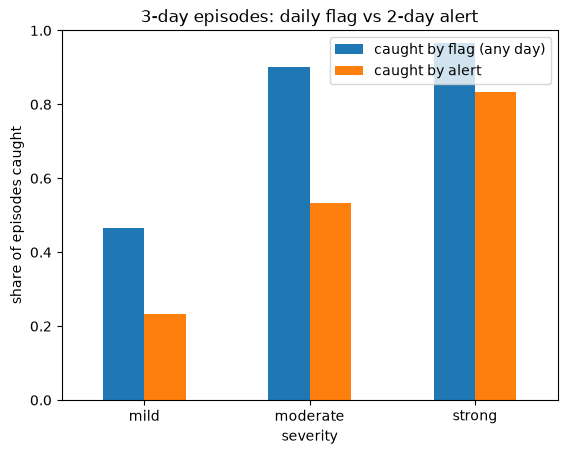

In [4]:
episode_results.plot.bar(rot=0)
plt.ylabel('share of episodes caught'); plt.ylim(0, 1)
plt.title('3-day episodes: daily flag vs 2-day alert')
plt.show()

We do lose detection: moderate episodes go from 90% to 53% and mild ones from 47% to 23%, because often only one of the three days gets flagged. Strong episodes are still mostly caught (83%).

We think this trade is worth it for the app. Missing a mild episode isn't a big deal, but too many false alarms would make people ignore all of them. The daily `flag` is still stored, so a doctor or the dashboard can still see single odd days. Only the **notification** waits for 2 days.

## 3. What about 3 days in a row?

Quick check by recounting the runs ourselves instead of changing the setting in the module.

In [5]:
runs = an.consecutive_flags(clean)
rows = []
for n_days in [1, 2, 3]:
    alert = runs >= n_days
    s = clean.assign(a=alert)
    rows.append({'days in a row': n_days, 'notifications per user per month': runs_started(s, 'a') / user_months})
pd.DataFrame(rows).set_index('days in a row').round(3)

,notifications per user per month
days in a row,
1,1.065
2,0.377
3,0.133


3 days would cut false alarms further, but a 3-day episode would then only alert if **every** day was flagged, and you'd only hear about it on day 3. We're keeping **2** as the default (`ALERT_DAYS` in `anomaly.py`).

## Summary
- added `alert` = flagged on 2 calendar days in a row (the daily `flag` is kept)
- false notifications on normal data went down about 3x
- on 3-day illness-like episodes: 83% of strong, 53% of moderate and 23% of mild ones still alert
- the cost is real, especially for moderate episodes. Lowering the threshold for the *second* day could win some back (not tried yet)
- next: unit tests, then connecting `score_days` to the backend